# Homework 2: VAE and VQ-VAE

## Task 1: Theory (5 pts)

### Problem 1: Gaussian VAE — what does optimizing ELBO guarantee? (1.5 pts)

Suppose VAE training reaches a global maximum of the ELBO. What can we then conclude about the generated data and the inferred latent variables? Use the following exactly solvable model to investigate this question. The calculations should support your diagnosis of what training has achieved and what would need to change.

Consider scalar observations with data distribution $p_{\text{data}}(x)=\mathcal N(\mu,1)$, where $\mu\in\mathbb R$ is fixed. The latent-variable model has prior $p(z)=\mathcal N(0,1)$ and decoder
$$
p_\theta(x\mid z)=\mathcal N(z+\theta,1).
$$
The encoder family is
$$
q_\phi(z\mid x)=\mathcal N(x+\phi,1),
\qquad \phi,\theta\in\mathbb R.
$$
The second argument of $\mathcal N$ denotes the variance. Train by maximizing the expected ELBO
$$
\mathbb E_{x\sim p_{\text{data}}}\mathcal L_{\phi,\theta}(x),
$$
where
$$
\begin{aligned}
\mathcal L_{\phi,\theta}(x)
&=\mathbb E_{z\sim q_\phi(\cdot\mid x)}\log p_\theta(x\mid z)\\
&\quad-D_{\mathrm{KL}}\bigl(q_\phi(z\mid x)\|p(z)\bigr).
\end{aligned}
$$

**(a) Optimize the ELBO (0.25 pts).** Compute the expected ELBO and find its unique global maximizer $(\phi^*,\theta^*)$.

**(b) Inspect the distributions (0.5 pts).** Derive the model marginal $p_\theta(x)$ and the exact posterior $p_\theta(z\mid x)$ for arbitrary $\theta$. Evaluate both at the optimum from (a). Also find the aggregated posterior
$$
q_{\text{agg},\phi^*}(z)
=\int p_{\text{data}}(x)\,q_{\phi^*}(z\mid x)\,dx
$$
and use it to assess the claim: “The KL term in the ELBO ensures that, at a global optimum, the distribution of encoded data equals the prior.”

**(c) What has training actually achieved? (0.75 pts).** Compute the average variational gap
$$
\mathbb E_{x\sim p_{\text{data}}}
\left[\log p_{\theta^*}(x)-\mathcal L_{\phi^*,\theta^*}(x)\right].
$$
A colleague suggests two ways to remove any remaining errors: train longer within the original families, or allow the encoder to be any conditional distribution while keeping the prior and decoder family fixed. Explain what each proposal can achieve for generation and for inference. Justify your conclusions using the restrictions of the given decoder and encoder.

Finish with a short conclusion: distinguish finding the best parameters, recovering the data distribution, and recovering the model's exact posterior. In particular, what would a zero variational gap certify, and would it suffice to certify correct generation?

```your solution```

### Problem 2: ELBO surgery — does an optimal VAE need informative latents? (1.5 pts)

An encoder may match the prior in aggregate while still retaining information about its input. But does maximizing the ELBO favor such an encoder over a collapsed one? Investigate this question in a binary-data model.

Let $p_{\text{data}}(x=0)=p_{\text{data}}(x=1)=1/2$, with scalar latent variable $z$ and fixed prior density $p(z)=\mathcal N(z\mid0,1)$. Write
$$
q_i(z)=q_{\boldsymbol\phi}(z\mid x=i),\qquad
q_{\text{agg},\boldsymbol\phi}(z)=\frac12\bigl(q_0(z)+q_1(z)\bigr),
$$
$$
K=\frac12\sum_{i=0}^1D_{\mathrm{KL}}(q_i\|p).
$$
You may use the Lecture 4 identities without proof:
$$
K=\mathbb I_q[x,z]+D_{\mathrm{KL}}(q_{\text{agg},\boldsymbol\phi}\|p),
\qquad
\mathbb I_q[x,z]=\frac12\sum_{i=0}^1D_{\mathrm{KL}}(q_i\|q_{\text{agg},\boldsymbol\phi}).
$$
Use natural logarithms. Call the encoder **collapsed to the prior** if $q_0=q_1=p$.

**(a) Construct an informative encoder (0.5 pts).** Construct two normalized densities $q_0,q_1$ whose aggregate is exactly $p$, but for which observing $z$ identifies the input $x$ without error. The conditional densities need not be Gaussian. Verify these properties and calculate $\mathbb I_q[x,z]$ and $K$.

**(b) Compare complete generative models (1 pt).** Allow a Bernoulli decoder
$$
p_{\boldsymbol\theta}(x=1\mid z)=r(z),\qquad
p_{\boldsymbol\theta}(x=0\mid z)=1-r(z),
$$
where $r(z)$ may be any function with values in $[0,1]$, including the endpoints. For each of the two encoders — your construction from (a) and the collapsed encoder — find a decoder that maximizes the average ELBO
$$
\overline{\mathcal L}
=\underbrace{\frac12\sum_{i=0}^1\mathbb E_{z\sim q_i}
\log p_{\boldsymbol\theta}(x=i\mid z)}_{R}\; - K.
$$
Calculate $R$, $K$, $\overline{\mathcal L}$ and the generated probabilities $p_{\boldsymbol\theta}(x=0)$ and $p_{\boldsymbol\theta}(x=1)$ for both models. Determine whether either model is a global maximizer of the ELBO over all normalized encoders and all decoders in this family; justify your answer.

Conclude: in this model, does a globally maximal ELBO together with the correct generated data distribution guarantee that the latent code retains information about the input? Explain how the reconstruction term and the prior penalty account for your comparison.


```
your solution
```

### Problem 3: VAE gradients — can an exact encoder still receive noisy updates? (2 pts)

At an exact variational posterior, the ELBO is maximal with respect to the encoder. Must a gradient computed from one latent sample also vanish? Investigate how the choice of an unbiased gradient estimator affects this question.

Fix an observation $\mathbf x$ and the generative parameters $\boldsymbol\theta$. Use a differentiable reparametrization
$$
\boldsymbol\epsilon\sim p(\boldsymbol\epsilon),\qquad
\mathbf z=g_{\boldsymbol\phi}(\mathbf x,\boldsymbol\epsilon)
\sim q_{\boldsymbol\phi}(\mathbf z\mid\mathbf x),
$$
where the noise distribution is independent of $\boldsymbol\phi$. Define the full Monte Carlo ELBO estimate
$$
\begin{aligned}
\widehat{\mathcal L}_{\boldsymbol\phi}(\boldsymbol\epsilon)
&=\log p_{\boldsymbol\theta}(\mathbf x,\mathbf z)
-\log q_{\boldsymbol\phi}(\mathbf z\mid\mathbf x),\\
\mathcal L(\boldsymbol\phi)
&=\mathbb E_{\boldsymbol\epsilon}
\widehat{\mathcal L}_{\boldsymbol\phi}(\boldsymbol\epsilon).
\end{aligned}
$$
Let $\mathbf G_{\mathrm{full}}=\nabla_{\boldsymbol\phi}\widehat{\mathcal L}_{\boldsymbol\phi}$, differentiating through the sample while keeping $\boldsymbol\epsilon$ fixed. Here both log-density terms are evaluated at the same sample; no KL term is integrated analytically.

Assume smooth positive densities on a common support independent of $\boldsymbol\phi$, and that the required derivatives and expectations may be interchanged and the gradient variances are finite.

**(a) Find a removable gradient term (0.75 pts).** Expand $\mathbf G_{\mathrm{full}}$ by the chain rule, distinguishing dependence on $\boldsymbol\phi$ through $\mathbf z$ from explicit dependence at fixed $\mathbf z$. Identify a term that has expectation zero for every $\boldsymbol\phi$, and prove this fact. Remove it to construct another estimator $\mathbf G_{\mathrm{new}}$ and show that
$$
\mathbb E\mathbf G_{\mathrm{new}}
=\mathbb E\mathbf G_{\mathrm{full}}
=\nabla_{\boldsymbol\phi}\mathcal L.
$$

**(b) Analyze exact inference (0.75 pts).** Suppose that at $\boldsymbol\phi^*$,
$$
q_{\boldsymbol\phi^*}(\mathbf z\mid\mathbf x)
=p_{\boldsymbol\theta}(\mathbf z\mid\mathbf x).
$$
Prove that your new estimator vanishes for every noise sample. Determine what remains in $\mathbf G_{\mathrm{full}}$ and explain why it need not vanish sample by sample, even though its expectation does.

Describe how to compute $\mathbf G_{\mathrm{new}}$ using stop-gradient. Specify which dependence is stopped and which paths through $\mathbf z$ must remain. The operator $\operatorname{sg}$ leaves a value unchanged in the forward pass and gives derivative zero in the backward pass.

**(c) Check a Gaussian example and interpret the result (0.5 pts).** For a scalar latent, take
$$
\begin{aligned}
p_{\boldsymbol\theta}(z\mid\mathbf x)&=\mathcal N(0,1),
&q_\phi(z\mid\mathbf x)&=\mathcal N(\phi,1),\\
z&=\phi+\epsilon,
&\epsilon&\sim\mathcal N(0,1).
\end{aligned}
$$
Compute $\mathcal L(\phi)$ up to a constant independent of $\phi$, both gradient estimators, and their expectations and variances for arbitrary $\phi$. Compare them at the exact posterior.

Conclude: what does unbiasedness guarantee, and what can still differ between two unbiased estimators of the same gradient? State precisely where your general proof guarantees zero variance; it need not establish a variance ordering elsewhere.

```
your solution
```

Now it time to move on to practical part of homework.

In our course we will use a small util [package](https://github.com/r-isachenko/dgm_utils) with some usefull functions for loading and visualizing the images and training curves. In each homework there will be a cell with installing this package. Please read carefully the sources of the functions from this package. It could help you to solve the tasks.

In [ ]:
COMMIT_HASH = "b8b4de3057ea4cafc3f263bfcf314f679b637db1"
!if [ -d dgm_utils ]; then rm -Rf dgm_utils; fi
!git clone https://github.com/r-isachenko/dgm_utils.git
%cd dgm_utils
!git checkout {COMMIT_HASH}
!pip install ./
%cd ./..
!rm -Rf dgm_utils

In [ ]:
from dgm_utils import train_model
from dgm_utils import show_samples, visualize_images, load_dataset
from dgm_utils import BaseModel

In [ ]:
import numpy as np
from typing import Tuple, Optional

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data

if torch.cuda.is_available():
    DEVICE = "cuda"
    print('GPU found :)')
else:
    DEVICE = "cpu"
    print('GPU not found :(')

## Task 2: ViT Model (2 pts)

We begin by introducing a **Vision Transformer (ViT)** architecture that will serve as the encoder and decoder for both the VAE and VQ-VAE generative models. In contrast to conventional CNN-based approaches that process an image as a 2D grid of pixels using local convolutional filters, ViT partitions the image into non-overlapping patches and maps each patch to a vector in a learnable embedding space. This representation allows us to reinterpret the image as a sequence of tokens, making it compatible with Transformer architectures originally designed for sequential data processing.

Let us begin by defining the Transformer block, which serves as the fundamental building component of the ViT architecture. It is implemented as follows:
\begin{gather}
    \mathbf{n}^l = \text{layer\_norm}_1\left(\mathbf{h}^l\right), \notag \\
    \mathbf{a}^l = \mathbf{h}^l + \text{multihead\_attention}\left(\mathbf{n}^l\right), \notag \\
    \mathbf{h}^{l+1} = \mathbf{a}^l + \text{MLP}\left(\text{layer\_norm}_2\left(a^l\right)\right). \notag
\end{gather}

The $l^{\text{th}}$ block receives a tensor $\mathbf{h}^l$ of shape `(batch_size, patch_num, emb_dim)`, where `emb_dim` is a hyperparameter that defines the dimensionality of the embeddings.

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(
            self,
            embed_dim: int,
            num_heads: int,
            # this is for conviniance
            attention_class: nn.Module = nn.MultiheadAttention,
        ) -> None:
        super().__init__()
        assert embed_dim % num_heads == 0

        self.mha = attention_class(
            embed_dim, num_heads, batch_first=True
        )
        # ====
        # your code
        # define basic layers of Transformer:
        # 1) LayerNorm (https://docs.pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html)
        # 2) some MLP

        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # here you have to implement formulas that described above.

        # ====
        return x


def test_transformer_block() -> None:
    block = TransformerBlock(embed_dim=12, num_heads=4)
    x = torch.zeros(4, 28, 12)
    assert x.shape == block(x).shape

test_transformer_block()

Next, we define two projection layers that map images to sequences of flattened patches and reconstruct them back to the image space.

In [ ]:
class PatchProjection(nn.Module):
    def __init__(
        self, num_channels: int, dim: int, patch_shape: Tuple[int, int],
    ):
        super().__init__()
        self.proj = nn.Conv2d(
            num_channels, dim, kernel_size=patch_shape, stride=patch_shape
        )

    def forward(self, x: torch.Tensor):
        # ====
        # your code
        # do following
        # 1) convolution with kernel_size=stride=patch_shape:
        #      splits the image into non-overlapping patches
        #      and projects each patch to `dim`
        #      (B, C, H, W) -> (B, dim, H', W'),
        #      where H' = H // P_h and W' = W // P_w
        # 2) flatten patch grid to tokens:
        #      (B, dim, H', W') -> (B, dim, N), where N = H' * W'
        # 3) transpose to token-major format:
        #      (B, dim, N) -> (B, N, dim)

        # ====
        return x

class ImageProjection(nn.Module):
    def __init__(
        self,
        dim: int,
        num_channels: int,
        patch_shape: Tuple[int, int],
        image_shape: Tuple[int, int],
    ):
        super().__init__()
        self.num_channels = num_channels
        self.patch_shape = patch_shape
        self.image_shape = image_shape

        patch_dim = num_channels * patch_shape[0] * patch_shape[1]
        self.proj = nn.Linear(dim, patch_dim)

        self.refine = nn.Sequential(*[
            nn.Conv2d(num_channels, 2 * num_channels, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(2 * num_channels, 2 * num_channels, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(2 * num_channels, num_channels, kernel_size=1)
        ])

    def forward(self, x: torch.Tensor):
        # ====
        # your code
        # 1) project each token back to patch pixels:
        #      (B, N, dim) -> (B, N, C * P_h * P_w)
        # 2) restore patch grid and patch shape:
        #      (B, N, C * P_h * P_w) -> (B, H', W', P_h, P_w, C)
        # 3) move channels first and interleave grid with patch pixels:
        #      (B, H', W', P_h, P_w, C) -> (B, C, H', P_h, W', P_w)
        # 4) Merge dimensions to reconstruct the image:
        #      (B, C, H', P_h, W', P_w) -> (B, C, H, W)
        # 5) apply CNN to reduce blocky patch artifacts

        # ====
        return x

def test_patch_and_image_projection():
    x = torch.zeros((2, 3, 32, 32))
    patch_shape = (8, 8)
    image_shape = (32, 32)
    dim = 64
    num_channels = 3

    patch_projection = PatchProjection(
        num_channels=num_channels, dim=dim, patch_shape=patch_shape
    )
    image_projection = ImageProjection(
        dim=dim,
        num_channels=num_channels,
        patch_shape=patch_shape,
        image_shape=image_shape,
    )

    tokens = patch_projection(x)
    assert tokens.shape == (2, 16, dim), (
        f"PatchProjection.forward returned wrong shape: got {tuple(tokens.shape)}, "
        f"expected (2, 16, {dim}). Input x shape was {tuple(x.shape)}, "
        f"patch_shape={patch_shape} gives 4x4=16 patches for image_shape={image_shape}."
    )

    decoded = image_projection(tokens)
    assert decoded.shape == (2, num_channels, *image_shape), (
        f"ImageProjection.forward returned wrong shape: got {tuple(decoded.shape)}, "
        f"expected (2, {num_channels}, {image_shape[0]}, {image_shape[1]}). "
        f"Tokens shape was {tuple(tokens.shape)}."
    )

test_patch_and_image_projection()

Now we can define Encoder and Decoder.

In [ ]:
class ViTEncoder(nn.Module):
    def __init__(
        self,
        num_channels: int,
        image_shape: Tuple[int, int],
        patch_shape: Tuple[int, int],
        embed_dim: int,
        num_heads: int,
        num_layers: int,
    ) -> None:
        super().__init__()

        assert (image_shape[0] % patch_shape[0] == 0 and image_shape[1] % patch_shape[1] == 0), \
            "Image dimensions must be divisible by the patch size."

        num_patches = (image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])

        # ====
        # your code
        # define here:
        # 1) patch projection using `PatchProjection`
        # 2) positional embeddings
        #      use nn.Parameter with shape (1, num_patches, embed_dim)
        # 3) transformer using `TransformerBlock`

        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # apply here defined networks
        # NOTE: positional embeddins are just summed with projected x

        # ====
        return x

def test_vit_encoder():
    x = torch.zeros((2, 3, 32, 32))
    num_channels = 3
    image_shape = (32, 32)
    patch_shape = (8, 8)
    embed_dim = 64
    num_heads = 1
    num_layers = 2

    encoder = ViTEncoder(
        num_channels=num_channels,
        image_shape=image_shape,
        patch_shape=patch_shape,
        embed_dim=embed_dim,
        num_heads=num_heads,
        num_layers=num_layers,
    )

    tokens = encoder(x)
    assert tokens.shape == (2, 16, embed_dim), (
        f"ViTEncoder.forward returned wrong shape: got {tuple(tokens.shape)}, "
        f"expected (2, 16, {embed_dim}). Input x shape was {tuple(x.shape)}. "
        f"image_shape={image_shape}, patch_shape={patch_shape} implies num_patches="
        f"{(image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])}."
    )

test_vit_encoder()

In [ ]:
class ViTDecoder(nn.Module):
    def __init__(
        self,
        num_channels: int,
        image_shape: Tuple[int, int],
        patch_shape: Tuple[int, int],
        embed_dim: int,
        num_heads: int,
        num_layers: int,
    ) -> None:
        super().__init__()

        assert (image_shape[0] % patch_shape[0] == 0 and image_shape[1] % patch_shape[1] == 0), \
            "Image dimensions must be divisible by the patch size."

        num_patches = (image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])

        # ====
        # your code
        # define here:
        # 1) positional embeddings
        #      use nn.Parameter with shape (1, num_patches, embed_dim)
        # 2) transformer using `TransformerBlock`
        # 3) image projection using `ImageProjection`

        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # apply here defined networks
        # NOTE: positional embeddins are just summed with projected x

        # ====
        return x

def test_vit_decoder():
    x = torch.zeros((2, 16, 64))
    num_channels = 3
    image_shape = (32, 32)
    patch_shape = (8, 8)
    embed_dim = 64
    num_heads = 1
    num_layers = 2

    decoder = ViTDecoder(
        num_channels=num_channels,
        image_shape=image_shape,
        patch_shape=patch_shape,
        embed_dim=embed_dim,
        num_heads=num_heads,
        num_layers=num_layers,
    )

    decoded = decoder(x)
    assert decoded.shape == (2, num_channels, *image_shape), (
        f"ViTDecoder.forward returned wrong shape: got {tuple(decoded.shape)}, "
        f"expected (2, {num_channels}, {image_shape[0]}, {image_shape[1]}). "
        f"Input x shape was {tuple(x.shape)}. "
        f"Expected x to be (B, num_patches, embed_dim) with num_patches="
        f"{(image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])} "
        f"and embed_dim={embed_dim}."
    )

test_vit_decoder()

## Task 3: ViTVAE on CIFAR10 (4 pts)

In this task you will implement VAE model for CIFAR10 dataset.

Let download and visualize samples from the dataset.

In [ ]:
train_data, _, test_data, _ = load_dataset("cifar10", flatten=False, binarize=False)
visualize_images(train_data, "CIFAR10 samples")

Now it is time to define our model. Our model will have the following structure:

* During VAE training, the prior distribution is standard Normal ($p(\mathbf{z}) = \mathcal{N}(0, I)$).
* Variational posterior distribution (or encoder) is $q(\mathbf{z} | \mathbf{x}, \boldsymbol{\phi}) = \mathcal{N}(\boldsymbol{\mu}_{\boldsymbol{\phi}}(\mathbf{x}), \boldsymbol{\Sigma}_{\boldsymbol{\phi}}(\mathbf{x}))$. Here $\boldsymbol{\phi}$ denotes all parameters of the encoder neural network. We will assume that covariance matrice $\boldsymbol{\Sigma}_{\boldsymbol{\phi}}(\mathbf{x})$ is diagonal.
* Generative distribution (or decoder) is $p(\mathbf{x} | \mathbf{z}, \boldsymbol{\theta}) = \mathcal{N}(\boldsymbol{\mu}_{\boldsymbol{\theta}}(\mathbf{z}), \boldsymbol{\Sigma}_{\boldsymbol{\theta}}(\mathbf{z}))$. Here $\boldsymbol{\theta}$ denotes all parameters of the decoder neural network. Please note, that here we will use continuous distribution for our variables $\mathbf{x}$.
* We do not fit the covariance matrix $\boldsymbol{\Sigma}_{\boldsymbol{\theta}}(\mathbf{z})$ in the generative distribution $p(\mathbf{x} | \mathbf{z}, \boldsymbol{\theta})$. We assume that it is identical ($\boldsymbol{\Sigma}_{\boldsymbol{\theta}}(\mathbf{z}) = \mathbf{I}$). We will use the $\boldsymbol{\mu}_{\boldsymbol{\theta}}(\mathbf{z})$ (mean of the generative distribution $p(\mathbf{x} | \mathbf{z}, \boldsymbol{\theta})$) as model samples.
* Our encoder and decoder will be ViT models from Task 2.
* Model objective is slightly modified ELBO:
$$
    \mathcal{L}(\boldsymbol{\phi}, \boldsymbol{\theta}) = \mathbb{E}_{q(\mathbf{z} | \mathbf{x}, \boldsymbol{\phi})} \log p(\mathbf{x} | \mathbf{z}, \boldsymbol{\theta}) - \beta KL (q(\mathbf{z} | \mathbf{x}, \boldsymbol{\phi}) || p(\mathbf{z})).
$$
Here we introduce the parameter $\beta$. It reweights KL term in the total loss. It a standard heuristics that allows to get more accurate model. In this exercise you have to play with it.

To express the expectation using noise independent of the encoder parameters, we will use the reparameterization trick.

To calculate the loss, we should derive
- $\log p(\mathbf{x} | \mathbf{z}, \boldsymbol{\theta})$, note that generative distribution is $\mathcal{N}(\boldsymbol{\mu}_{\boldsymbol{\theta}}(\mathbf{z}), \boldsymbol{\Sigma}_{\boldsymbol{\theta}}(\mathbf{z}))$.
- KL between $q(\mathbf{z} | \mathbf{x}, \boldsymbol{\phi}) = \mathcal{N}(\boldsymbol{\mu}_{\boldsymbol{\phi}}(\mathbf{x}), \boldsymbol{\Sigma}_{\boldsymbol{\phi}}(\mathbf{x}))$ and $\mathcal{N}(0, \mathbf{I})$.

Let start with the helper functions.

In [ ]:
def get_normal_KL(
    mean_1: torch.Tensor,
    log_std_1: torch.Tensor,
    mean_2: Optional[torch.Tensor] = None,
    log_std_2: Optional[torch.Tensor] = None,
) -> torch.Tensor:
    if mean_2 is None:
        mean_2 = torch.zeros_like(mean_1)
    if log_std_2 is None:
        log_std_2 = torch.zeros_like(log_std_1)
    assert mean_1.shape == log_std_1.shape == mean_2.shape == log_std_2.shape
    # ====
    # your code
    # implement KL(p1 || p2), where
    # p1 = Normal(mean_1, exp(log_std_1) ** 2) and
    # p2 = Normal(mean_2, exp(log_std_2) ** 2)
    # NOTE: we consider the case of diagonal covariance matrix.

    # ====


def test_KL():
    assert np.isclose(
        get_normal_KL(
            torch.tensor(2), torch.tensor(3), torch.tensor(0), torch.tensor(0)
        ).numpy(),
        200.2144,
        rtol=1e-3,
    )
    assert np.isclose(
        get_normal_KL(
            torch.tensor(2), torch.tensor(3), torch.tensor(4), torch.tensor(5)
        ).numpy(),
        1.50925,
        rtol=1e-3,
    )
    assert np.allclose(
        get_normal_KL(
            torch.tensor((10, 10)), torch.tensor((2, 4)), torch.tensor((3, 5))
        ).numpy(),
        [49.2990, 1498.479],
        rtol=1e-3,
    )


test_KL()

In [ ]:
def get_normal_nll(
    x: torch.Tensor, mean: torch.Tensor, log_std: torch.Tensor
) -> torch.Tensor:
    # ====
    # your code
    # implement negative log likelihood -log p(x)
    # where p(x) = Normal(x | mean, exp(log_std) ** 2)
    # NOTE: we consider the case of diagonal covariance matrix

    # ====


def test_NLL():
    assert np.isclose(
        get_normal_nll(torch.tensor(2), torch.tensor(2), torch.tensor(3)).numpy(),
        3.9189,
        rtol=1e-3,
    )
    assert np.isclose(
        get_normal_nll(torch.tensor(5), torch.tensor(-3), torch.tensor(6)).numpy(),
        6.9191,
        rtol=1e-3,
    )
    assert np.allclose(
        get_normal_nll(
            torch.tensor((10, 10)), torch.tensor((2, 4)), torch.tensor((3, 5))
        ).numpy(),
        np.array([3.9982, 5.9197]),
        rtol=1e-3,
    )


test_NLL()

We are ready to implement VAE model for image dataset.

In [ ]:
class ViTVAE(BaseModel):
    def __init__(
        self,
        latent_dim: int,
        num_channels: int,
        image_shape: Tuple[int, int],
        patch_shape: Tuple[int, int],
        embed_dim: int,
        num_heads: int,
        num_layers: int,
        beta: float = 1,
    ) -> None:
        super().__init__()

        self.latent_dim = latent_dim
        self.beta = beta

        self.embed_dim = embed_dim
        self.num_patches = (image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])
        assert latent_dim > 0 and latent_dim % self.num_patches == 0
        self.patch_dim = latent_dim // self.num_patches
        # ====
        # your code
        # define here ViT encoder and decoder
        # also implement two linear layers for
        # embddings to latent and latent to embddings projections
        # NOTE: latent_proj outputs 2 * patch_dim; embed_proj maps patch_dim to embed_dim.
        # This preserves the correspondence between patches and latent tokens,
        # which may help train the TarFlow prior.

        # ====

    def prior(self, n: int) -> torch.Tensor:
        # ====
        # your code
        # return n samples from prior distribution (we use standart normal for prior)

        # ====
        return z

    def forward(self, x: torch.Tensor) -> tuple:
        # ====
        # your code
        # 1) apply encoder to get mu_z, log_std_z
        # 2) apply reparametrization trick (use self.prior)
        # 3) apply decoder to get mu_x (which corresponds to reconstructed x)
        # NOTE: apply both projections to each token independently;
        # flatten after latent_proj and reshape into tokens before embed_proj.

        # ====
        return mu_z, log_std_z, x_recon

    def loss(self, x: torch.Tensor) -> dict:
        # ====
        # your code
        # 1) make forward step to get mu_z, log_std_z, x_recon
        # 2) calculate recon_loss (use get_normal_nll)
        # 3) calcucalte kl_loss (use get_normal_KL)

        # ====
        return {
            "elbo_loss": recon_loss + self.beta * kl_loss,
            "recon_loss": recon_loss,
            "kl_loss": kl_loss,
        }

    def sample(self, n: int) -> np.ndarray:
        with torch.no_grad():
            # ====
            # your code
            # 1) generate prior samples
            # 2) apply decoder

            # ====
            samples = torch.clamp(x_recon, -1, 1)
        return samples.cpu().numpy() * 0.5 + 0.5

That is all! We are ready to train our model.

**NOTE:** focus on improving reconstruction quality rather than sample quality; we will improve sample quality later.

In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE =
EPOCHS =
LR =
LAT_DIM =
BETA =  # focus here better reconstruction quality

EMB_DIM =
NUM_HEADS =
NUM_LAYERS =
# ====

# we center the data, because it helps the model to fit
centered_train_data = train_data * 2 - 1
centered_test_data = test_data * 2 - 1

train_loader = data.DataLoader(centered_train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(centered_test_data, batch_size=BATCH_SIZE)

model = ViTVAE(
    latent_dim=LAT_DIM,
    num_channels=3,
    image_shape=(32, 32),
    patch_shape=(4, 4),
    embed_dim=EMB_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    beta=BETA,
)

# choose any optimizer/scheduler as you want
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

train_model(
    model,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    device=DEVICE,
    n_samples=16,
    visualize_samples=True,
    loss_key="elbo_loss",
)

Now we could visualize the model outputs.

1. We could sample new images from our model (sample latent variable from the prior and apply the decoder).
2. We could visualize image reconstructions (apply the encoder and the decoder to the fixed image).
3. Visualize interpolations (apply the encoder to two images $\mathbf{x}_1$ and $\mathbf{x}_2$ to obtain the latent variables $\mathbf{z}_1$ and $\mathbf{z}_2$, apply the decoder to the latent variables $\mathbf{z}$ lying on the segment between $\mathbf{z}_1$ and $\mathbf{z}_2$).

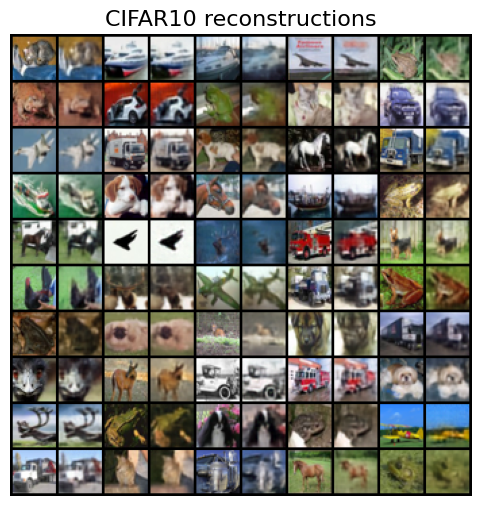

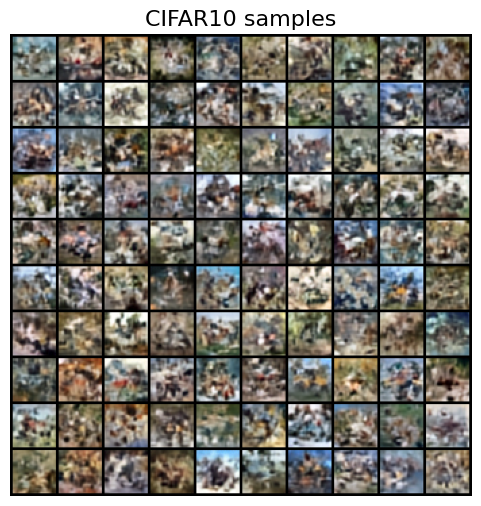

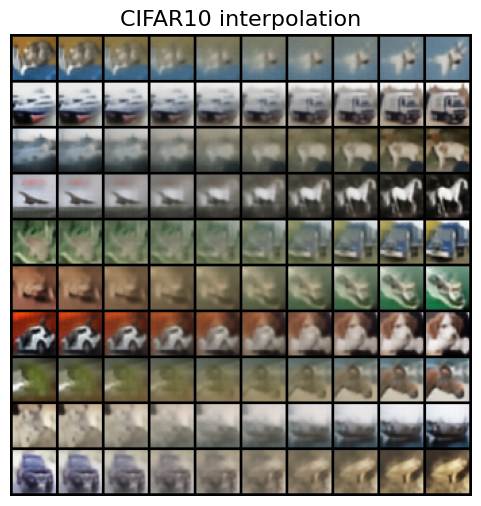

In [ ]:
samples = model.sample(100)

x = torch.from_numpy(centered_test_data[:50]).to(model.device)
with torch.no_grad():
    mu_z, _, x_recon = model(x)
    x_recon = torch.clamp(x_recon, -1, 1)
reconstructions = torch.stack((x, x_recon), dim=1).reshape(-1, 3, 32, 32) * 0.5 + 0.5
reconstructions = reconstructions.cpu().numpy()

x = torch.from_numpy(centered_test_data[:20]).to(model.device)
with torch.no_grad():
    embeddings = model.encoder(x)
    z, _ = model.latent_proj(embeddings).chunk(2, dim=-1)

    embeddings = model.embed_proj(z)
    embeddings1, embeddings2 = embeddings.chunk(2, dim=0)

    interps = [model.decoder(embeddings1 * (1 - alpha) + embeddings2 * alpha) for alpha in np.linspace(0, 1, 10)]
    interps = torch.stack(interps, dim=1).reshape(-1, 3, 32, 32)
    interps = torch.clamp(interps, -1, 1) * 0.5 + 0.5
interps = interps.cpu().numpy()

show_samples(reconstructions, 'CIFAR10 reconstructions')
show_samples(samples, 'CIFAR10 samples')
show_samples(interps, 'CIFAR10 interpolation')

### Training of prior normalizing flow

The standard Normal prior may not match the latent distribution produced by our trained VAE. To improve sample quality, we will fit a TarFlow prior to these latents, keeping the encoder and decoder fixed. TarFlow learns to transform VAE latents into standard Normal noise. For generation, we sample this noise, apply the inverse flow, and pass the resulting latents through the VAE decoder.

To implement this prior, reuse your `MultiheadAttention`, `TarFlowBlock` and `TarFlow` implementations from Homework 1.

Let us start from `MultiheadAttention`.

**NOTE:** Consider batch-first masked attention.

In [ ]:
class MultiheadAttention(nn.MultiheadAttention):
    def __init__(
        self,
        embed_dim: int,
        num_heads: int,
        batch_first: bool = True
    ) -> None:
        super().__init__(embed_dim, num_heads, batch_first=batch_first)

    def get_attention_mask(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # define attention mask, it should contain
        # 1) zeros under and on the main diagonal
        # 2) minus Inf above the main diagonal

        # ====
        return attention_mask

    def forward(
        self,
        query: torch.Tensor,
        key: torch.Tensor,
        value: torch.Tensor,
        key_padding_mask: Optional[torch.Tensor] = None,
        need_weights: bool = True,
        attn_mask: Optional[torch.Tensor] = None,
        average_attn_weights: bool = True,
        is_causal: bool = False
    ) -> Tuple[torch.Tensor, ...]:
        mask = self.get_attention_mask(query)
        return super().forward(
            query, key, value,
            attn_mask=mask,
            key_padding_mask=key_padding_mask,
            need_weights=need_weights,
            average_attn_weights=average_attn_weights,
            is_causal=is_causal
        )


def test_attention_mask() -> None:
    x = torch.zeros(4, 2, 16)
    mask = np.array([[0.0, -np.inf], [0.0, 0.0]])
    layer = MultiheadAttention(16, 8)
    attention_mask = layer.get_attention_mask(x)

    assert attention_mask.size() == (x.shape[1], x.shape[1]), \
        "Attention mask must be square with shape (seq_len, seq_len)."

    assert np.allclose(attention_mask.detach().cpu().numpy(), mask), \
        "Mask must be 0 on/under diagonal and -inf strictly above diagonal."

    out, _ = layer(x, x, x, need_weights=False)

    assert x.size() == out.size(), \
        "MultiheadAttention output must have the same shape as the input (batch_size, seq_len, embed_dim)."


test_attention_mask()

`TarFlowBlock` retains the same flow transformations; only its Transformer setup needs to be adapted to Task 2 and batch-first masked attention.

In [ ]:
class TarFlowBlock(nn.Module):
    def __init__(
        self,
        patch_dim: int,
        num_patches: int,
        embed_dim: int,
        num_heads: int,
        num_layers: int,
        reverse_order: bool,
    ) -> None:
        super().__init__()
        self.reverse_order = reverse_order

        # ====
        # your code
        # 1) define projecting layer for each patch from patch_dim to embed_dim
        # 2) define learned positional embeddings of shape (1, num_patches, embed_dim)
        # 3) stack num_layers TransformerBlock instances with masked MultiheadAttention
        # 4) define a head that predicts a shift and a log-scale for each patch
        # NOTE: initialize the head's weight and bias to zero so the flow block
        # starts as the identity transformation; this will improve stability of training

        # ====

    def predict_parameters(self, x: torch.Tensor) -> torch.Tensor:
        # NOTE: Transformer need not be invertible; it only predicts
        # the parameters of the affine transformation.
        length = x.size(1)

        # ====
        # your code
        # 1) arrange positional embeddings in the same order as the patches in x
        # 2) cut positional embeddings by length of x
        #    (during inverse/generation, x is a partial sequence)
        # 3) project the patches to embed_dim and add their positional embeddings
        # 4) apply Transformer blocks in batch-first format (B, N, embed_dim)
        # 5) apply head

        # ====
        return parameters

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        if self.reverse_order:
            x = x.flip(1)

        # ====
        # your code
        # 1) predict parameters and shift them right
        #    (parameters for x_i must depend only on x_<i)
        # 2) apply the affine transformation and compute log-determinant

        # ====

        if self.reverse_order:
            z = z.flip(1)
        return z, log_det

    def inverse(self, z: torch.Tensor) -> torch.Tensor:
        if self.reverse_order:
            z = z.flip(1)

        # ====
        # your code
        # 1) copy the first patch (it unchanged by the formula)
        # 2) for each next patch, predict its parameters from the reconstructed prefix
        #    (use the last prediction, which forward shifts to that patch)
        # 3) apply inverted affine transformation and append the recovered patch to x

        # ====

        return x.flip(1) if self.reverse_order else x


def test_tarflow_block() -> None:
    block = TarFlowBlock(
        patch_dim=2, num_patches=4, embed_dim=12,
        num_heads=4, num_layers=1, reverse_order=True,
    )
    with torch.no_grad():
        block.head.weight.normal_(std=0.01)
        block.head.bias.normal_(std=0.01)

    x = torch.randn(2, 4, 2)
    z, log_det = block(x)
    assert z.shape == x.shape and log_det.shape == (2,)
    assert torch.allclose(block.inverse(z), x, atol=1e-5)

    ordered_x = x.flip(1)
    parameters = block.predict_parameters(ordered_x)
    changed_x = ordered_x.clone()
    changed_x[:, 2:] += 1.0
    changed_parameters = block.predict_parameters(changed_x)
    assert torch.allclose(parameters[:, :2], changed_parameters[:, :2], atol=1e-6)


test_tarflow_block()

The main input-shape adaptation is in `patchify` and `unpatchify`, which convert between flat VAE latents `(B, latent_dim)` and latent tokens `(B, num_patches, patch_dim)`, preserving their original order. Image-specific scaling and clipping should also be removed.

In [ ]:
class TarFlow(BaseModel):
    def __init__(
        self,
        latent_dim: int,
        patch_dim: int,
        embed_dim: int,
        num_heads: int,
        num_layers: int,
        num_blocks: int,
    ) -> None:
        super().__init__()
        assert patch_dim > 0 and latent_dim % patch_dim == 0
        assert latent_dim // patch_dim >= 2 and num_blocks >= 2
        self.latent_dim = latent_dim
        self.patch_dim = patch_dim
        num_patches = latent_dim // patch_dim

        self.prior = torch.distributions.Normal(
            loc=torch.tensor(0.0), scale=torch.tensor(1.0)
        )
        # ====
        # your code
        # stack flow blocks with alternating forward and reversed patch order

        # ====

    def patchify(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # split the latent vector into groups without changing their values
        # (B, latent_dim) -> (B, latent_dim // patch_dim, patch_dim)

        # ====
        return patches

    def unpatchify(self, patches: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # put the coordinate groups back into the original latent vector
        # (B, latent_dim // patch_dim, patch_dim) -> (B, latent_dim)

        # ====
        return x

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        # NOTE: VAE latents are continuous and unbounded.
        # Reshaping the vector adds zero to the log-determinant.
        log_det = x.new_zeros(x.shape[0])

        # ====
        # your code
        # 1) prepare latent coordinate groups
        # 2) apply all flow blocks and accumulate their log-determinants
        # 3) unpatchify to obtain the transformed latent vector

        # ====

        return z, log_det

    def inverse(self, z: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # 1) prepare latent coordinate groups
        # 2) apply all inverse flow blocks
        # 3) unpatchify to obtain the original latent vector

        # ====
        return x

    def log_prob(self, x: torch.Tensor) -> torch.Tensor:
        self.prior.loc = self.prior.loc.to(self.device)
        self.prior.scale = self.prior.scale.to(self.device)
        # ====
        # your code
        # compute log probability of x using CoV formula
        # use self.prior to compute log probability of latent

        # ====
        return log_prob

    def loss(self, x: torch.Tensor) -> dict:
        return {"nll_loss": -self.log_prob(x).mean()}

    @torch.no_grad()
    def sample(self, num_samples: int) -> np.ndarray:
        z = torch.randn(num_samples, self.latent_dim, device=self.device)
        samples = self.inverse(z).cpu().numpy()
        return samples


def test_tarflow() -> None:
    model = TarFlow(
        latent_dim=8, patch_dim=2,
        embed_dim=12, num_heads=4, num_layers=1, num_blocks=2,
    )
    x = torch.randn(2, 8)
    assert torch.equal(model.unpatchify(model.patchify(x)), x)

    z, log_det = model(x)
    assert z.shape == x.shape and log_det.shape == (2,)
    assert torch.allclose(z, x)
    assert torch.allclose(log_det, torch.zeros_like(log_det))
    assert torch.allclose(model.inverse(z), x, atol=1e-5)

    # Check inversion after moving away from the identity initialization.
    with torch.no_grad():
        for block in model.blocks:
            block.head.weight.normal_(std=0.01)
            block.head.bias.normal_(std=0.01)
    z, _ = model(x)
    assert torch.allclose(model.inverse(z), x, atol=1e-5)
    assert torch.isfinite(model.loss(x)["nll_loss"])
    samples = model.sample(3)
    assert isinstance(samples, np.ndarray) and samples.shape == (3, 8)
    assert np.isfinite(samples).all()


test_tarflow()

Now let us prepare train and test latent samples. Sample latent variables from the VAE posterior using the centered images, evaluation mode and no gradients. Then train TarFlow as in Homework 1.

In [ ]:
model.eval()

# ====
# your code
# get samples from the VAE posterior for train and test images
# 1) process centered images in batches without gradients
# 2) apply encoder and latent_proj to get mu_z and log_std_z
# 3) sample z using the reparametrization trick (reuse model.prior)
# 4) collect NumPy arrays of shape (dataset_size, model.latent_dim)

# ====

assert isinstance(train_latents, np.ndarray)
assert isinstance(test_latents, np.ndarray)
assert train_latents.shape == (len(centered_train_data), model.latent_dim)
assert test_latents.shape == (len(centered_test_data), model.latent_dim)

In [ ]:
# ====
# your code
# choose these parameters
EPOCHS =
BATCH_SIZE =
LR =

PATCH_DIM = model.patch_dim  # one VAE latent token
EMB_DIM =
NUM_HEADS =
NUM_LAYERS =
NUM_BLOCKS =
# ====

prior_model = TarFlow(
    latent_dim=model.latent_dim,
    patch_dim=PATCH_DIM,
    embed_dim=EMB_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    num_blocks=NUM_BLOCKS,
)

train_loader = data.DataLoader(train_latents, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(test_latents, batch_size=BATCH_SIZE)

# choose any optimizer/scheduler as you want
optimizer = torch.optim.AdamW(prior_model.parameters(), lr=LR)

train_model(
    prior_model,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    device=DEVICE,
    gradient_clip_val=1.0,
    loss_key="nll_loss",
    visualize_samples=False,
    use_amp=True,
)

Now we are ready to sample from our VAE model. The difference here is that we sample latent variables from the TarFlow prior instead of the standard Normal prior.

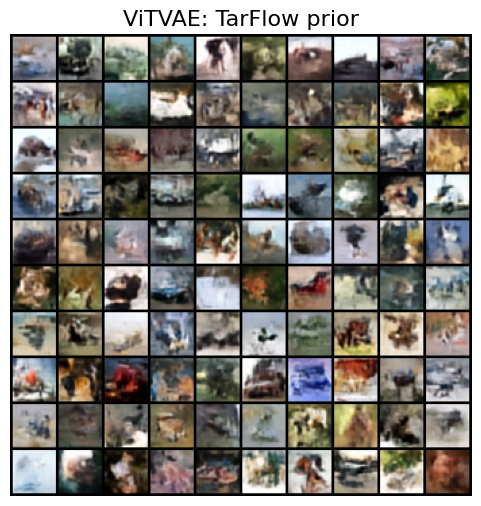

In [ ]:
N_SAMPLES = 100
model.eval()
prior_model.eval()

with torch.no_grad():
    z = torch.from_numpy(prior_model.sample(N_SAMPLES)).to(model.device)
    embeddings = model.embed_proj(z.reshape(-1, model.num_patches, model.patch_dim))
    samples = model.decoder(embeddings)
    samples = torch.clamp(samples, -1, 1).cpu().numpy() * 0.5 + 0.5

show_samples(samples, title="ViTVAE: TarFlow prior")

Hopefully, the samples look better now and better than mine :)

## Task 4: VQ-VAE on CIFAR10 (4 pts)

### Training of VQ-VAE model

In this part you will train [VQ-VAE](https://arxiv.org/abs/1711.00937) model that we have discussed at the lecture (see also [VQ-VAE-2](https://arxiv.org/abs/1906.00446) paper). We will use the same CIFAR10 dataset as in previous task.

VQ-VAE model is a VAE model with discrete latent variable.  

**Reminder:**
* We define  dictionary (word book) space $\{\mathbf{e}_k\}_{k=1}^K$, where $\mathbf{e}_k \in \mathbb{R}^C$, $K$ is the size of the dictionary.
* $\mathbf{z}_e = \text{NN}_e(\mathbf{x}, \boldsymbol{\phi})$ - continuous output of encoder network.
* $\mathbf{z}_q = \mathbf{e}_{k^*}$ is a quantized representation, where $k^* = \text{argmin}_k \| \mathbf{z} - \mathbf{e}_k \|$. It is simple nearest neighbor look up.
* Out deterministic variational posterior:
$$
  q(c = k^* | \mathbf{x}, \boldsymbol{\phi}) = \begin{cases}
  1 , \quad \text{for } k^* = \text{argmin}_k \| \mathbf{z}_e - \mathbf{e}_k \|; \\
  0, \quad \text{otherwise}.
\end{cases}
$$
* Prior distribution is uniform: $p(c) = \text{Uniform}\{1, \dots, K\}$.
* KL divergence between posterior and prior:
$$
  KL(q(c = k^* | \mathbf{x}, \boldsymbol{\phi}), p(c)) = \log K.
$$
* ELBO:
$$
		\mathcal{L} (\boldsymbol{\phi}, \boldsymbol{\theta})  = \mathbb{E}_{q(c | \mathbf{x}, \boldsymbol{\phi})} \log p(\mathbf{x} | \mathbf{e}_{c} , \boldsymbol{\theta}) - \log K =  \log p(\mathbf{x} | \mathbf{z}_q, \boldsymbol{\theta}) - \log K.
$$
* Vector quantization is non-differentiable operation. We will use **straight-through** gradient estimator (we will copy gradients from decoder input $\mathbf{z}_q$ to encoder output $\mathbf{z}_e$.

**Important modifications:**
Due to the straight-through gradient estimation of mapping from $\mathbf{z}_e$ to $\mathbf{z}_q$, the embeddings $\mathbf{e}$ receive no gradients from the ELBO.

Therefore, in order to learn the embedding space we add l2 loss (**codebook loss**) to move the embedding vectors $\mathbf{e}$ towards the encoder outputs $\mathbf{z}_e$.

Finally, since the volume of the embedding space is dimensionless, it can grow arbitrarily if the embeddings $\mathbf{e}$ do not train as fast as the encoder parameters. To make sure the encoder commits to an embedding and its output does not grow, we add a **commitment loss**.

Thus, the total training objective becomes:
$$
  \log p(\mathbf{x}| \mathbf{z}_q, \boldsymbol{\theta}) + \| \text{stop\_gradient}(\mathbf{z}_e) - \mathbf{e}\|_2^2 + \| \mathbf{z}_e - \text{stop\_gradient}(\mathbf{e})\|_2^2.
$$

Pay attention to the $\text{stop\_gradient}(*)$ operator.


Our first step is implement vector quantization procedure. It will also calculate two consistency losses.

In [ ]:
class VectorQuantizer(nn.Module):
    def __init__(
        self, num_embeddings: int = 128, embedding_dim: int = 16, beta: float = 0.25
    ) -> None:
        super().__init__()
        self.embedding_dim = embedding_dim
        self.num_embeddings = num_embeddings

        self.beta = beta

        # Initialize the embeddings which we will quantize.
        self.embedding = nn.Embedding(num_embeddings, embedding_dim)
        self.embedding.weight.data.uniform_(-1 / num_embeddings, 1 / num_embeddings)

    def get_code_indices(self, x: torch.Tensor) -> torch.Tensor:
        input_shape = x.shape[:-1]
        flattened = x.reshape(-1, self.embedding_dim)
        # ====
        # your code
        # 1) calculate distances from flatten inputs to embeddings
        # 2) find nearest embeddings to each input (use argmin op)

        # ====
        encoding_indices = encoding_indices.reshape(input_shape)
        return encoding_indices

    def get_quantized(self, encoding_indices: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # get embeddgins with appropriate indices

        # ====
        return quantized

    def forward(self, x: torch.Tensor) -> tuple:
        # ====
        # your code
        # 1) get indices
        # 2) get quantized latents
        # 3) calculate codebook and commitment loss
        #    do not afraid about stop_gradient op
        #    (use .detach() method for quantized latents and x)
        # 4) final loss is codebook_loss + beta * commitment_loss

        # ====

        # Straight-through estimator (think about it!).
        quantized = x + (quantized - x).detach()

        return quantized, loss

def test_vector_quantizer_tokens():
    x = torch.zeros((4, 16, 32))
    layer = VectorQuantizer(num_embeddings=128, embedding_dim=32)

    indices = layer.get_code_indices(x)
    assert indices.shape == (4, 16), (
        f"get_code_indices(x) returned wrong shape: got {tuple(indices.shape)}, "
        f"expected (4, 16). Input x shape was {tuple(x.shape)}."
    )

    quantized = layer.get_quantized(indices)
    assert quantized.shape == (4, 16, 32), (
        f"get_quantized(indices) returned wrong shape: got {tuple(quantized.shape)}, "
        f"expected (4, 16, 32). Indices shape was {tuple(indices.shape)}."
    )

    quantized, loss = layer(x)
    assert quantized.shape == (4, 16, 32), (
        f"layer(x) returned quantized with wrong shape: got {tuple(quantized.shape)}, "
        f"expected (4, 16, 32). Input x shape was {tuple(x.shape)}."
    )
    assert loss.shape == (), (
        f"layer(x) returned loss with wrong shape: got {tuple(loss.shape)}, "
        f"expected scalar shape (). Loss type was {type(loss)}."
    )

test_vector_quantizer_tokens()

Now we can define our VQ-VAE model.

In [ ]:
class ViTVQVAE(BaseModel):
    def __init__(
        self,
        num_channels: int,
        image_shape: Tuple[int, int],
        patch_shape: Tuple[int, int],
        num_embeddings: int,
        embed_dim: int,
        num_heads: int,
        num_layers: int,
        recon_loss_scale: float = 1.0,
    ) -> None:
        super().__init__()

        self.recon_loss_scale = recon_loss_scale

        self.num_embeddings = num_embeddings
        self.embed_dim = embed_dim
        self.num_patches = (image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])
        # ====
        # your code
        # define here ViT encoder and decoder
        # also implement vector quantization layer
        # NOTE: encoder and decoder works in space `num_patches * embed_dim`

        # ====

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        # ====
        # your code
        # 1) apply encoder
        # 2) apply vector quantizer (it returns quantized representation + vq_loss)
        # 3) apply decoder (it returns decoded samples)

        # ====
        return decoded, vq_loss

    def loss(self, x: torch.Tensor) -> dict:
        # ====
        # your code
        # 1) apply model
        # 2) compute mse loss for reconstruction

        # ====
        return {
            "total_loss": self.recon_loss_scale * recon_loss + vq_loss,
            "recon_loss": self.recon_loss_scale * recon_loss,
            "vq_loss": vq_loss,
        }

    def get_indices(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # 1) apply encoder
        # 2) get indices of codes using vector quantizer

        # ====
        return codebook_indices

    def prior(self, n: int) -> torch.Tensor:
        # ====
        # your code
        # prior distribution is uniform
        # 1) get samples from categorical distribution
        # 2) get quantized representations using vector quantizer

        # ====
        return quantized

    def sample(self, n: int) -> np.ndarray:
        with torch.no_grad():
            # ====
            # your code
            # 1) sample from prior distribution
            # 2) apply decoder

            # ====
            samples = torch.clamp(samples, -1, 1)
        return samples.cpu().numpy() * 0.5 + 0.5


def test_vqvae_model():
    model = ViTVQVAE(
        num_channels=1,
        image_shape=(32, 32),
        patch_shape=(8, 8),
        num_embeddings=4,
        embed_dim=128,
        num_heads=1,
        num_layers=1,
    ).to(DEVICE)
    x = torch.zeros((2, 1, 32, 32)).to(DEVICE)

    indices = model.get_indices(x)
    assert indices.shape == (2, 16), (
        f"model.get_indices(x) returned wrong shape: got {tuple(indices.shape)}, "
        f"expected (2, 16). Input x shape was {tuple(x.shape)}; "
        f"image_shape=(32, 32), patch_shape=(8, 8) implies num_patches=16."
    )

    losses = model.loss(x)
    assert isinstance(losses, dict), (
        f"model.loss(x) should return a dict, got {type(losses)} instead."
    )
    assert "total_loss" in losses, (
        f'model.loss(x) dict is missing key "total_loss". '
        f"Got keys: {list(losses.keys())}."
    )

    quantized = model.prior(10)
    assert quantized.shape == (10, 16, 128), (
        f"model.prior(10) returned wrong shape: got {tuple(quantized.shape)}, "
        f"expected (10, 16, 128). "
        f"Expected (n, num_patches, embed_dim) with n=10, num_patches=16, embed_dim=128."
    )

    decoded = model.decoder(quantized)
    assert decoded.shape == (10, 1, 32, 32), (
        f"model.decoder(quantized) returned wrong shape: got {tuple(decoded.shape)}, "
        f"expected (10, 1, 32, 32). Quantized shape was {tuple(quantized.shape)}."
    )

    sampled = model.sample(10)
    assert sampled.shape == (10, 1, 32, 32), (
        f"model.sample(10) returned wrong shape: got {tuple(sampled.shape)}, "
        f"expected (10, 1, 32, 32). Note: sample() returns a NumPy array."
    )


test_vqvae_model()

Let's train our model!

In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE =
EPOCHS =
LR =
RECON_SCALE =

NUM_EMB =
EMB_DIM =
NUM_HEADS =
NUM_LAYERS =
# ====

model = ViTVQVAE(
    num_channels=3,
    image_shape=(32, 32),
    patch_shape=(4, 4),
    num_embeddings=NUM_EMB,
    embed_dim=EMB_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    recon_loss_scale=RECON_SCALE
)

# we center the data, because it helps the model to fit
centered_train_data = train_data * 2 - 1
centered_test_data = test_data * 2 - 1

train_loader = data.DataLoader(centered_train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(centered_test_data, batch_size=BATCH_SIZE)

# choose any optimizer/scheduler as you want
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

train_model(
    model,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    device=DEVICE,
    n_samples=16,
    visualize_samples=True,
    use_amp=True,
)

Now we are able to sample from the trained model.

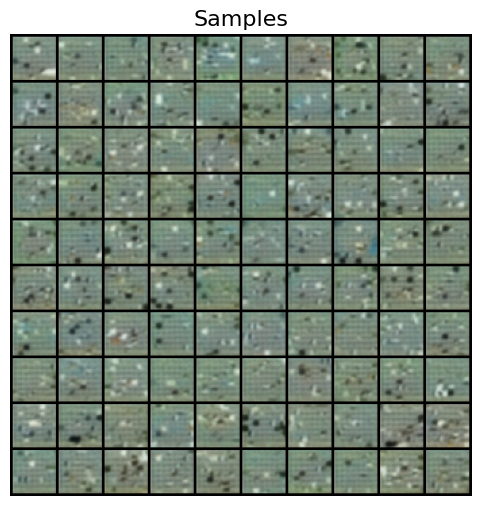

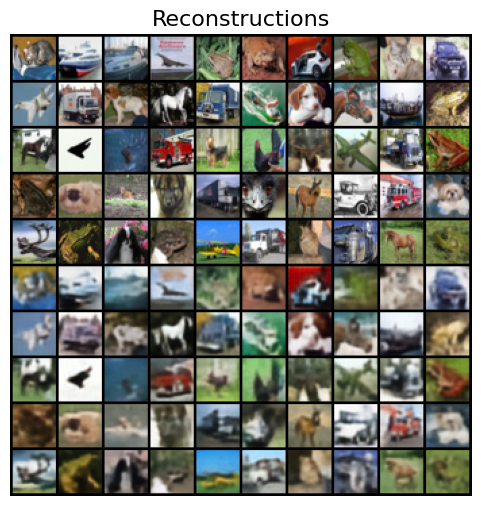

In [ ]:
# Samples
samples = model.sample(100)
show_samples(samples, title="Samples")

# Reconstructions
x = torch.from_numpy(centered_test_data[:50]).to(model.device)
with torch.no_grad():
    x_recon, _ = model(x)

x = torch.clamp(x, -1, 1) * 0.5 + 0.5
x_recon = torch.clamp(x_recon, -1, 1) * 0.5 + 0.5

x_recon = x_recon.cpu().numpy()
x = x.cpu().numpy()

reconstructions = np.concatenate((x, x_recon), axis=0)
reconstructions = reconstructions.astype("float32")
show_samples(reconstructions, title="Reconstructions")

As in the previous task, you will probably get poor samples :(

Don't worry, we will try to improve them in the same way! First, make sure your reconstructions are nearly perfect.

### Training of prior autoregressive model

The samples from our VQ-VAE model is not good enough. The authors of the original VQ-VAE paper proposed to train autoregressive model in the latent space after we trained VQ-VAE model.

Just as we used TarFlow to learn a continuous prior, we will train a autoregressive prior on the code indices produced by the trained VQ-VAE encoder, keeping the VQ-VAE fixed.

We will use a GPT model with the batch-first masked multi-head attention defined above.

In [ ]:
class GPT(BaseModel):
    def __init__(
        self,
        dim: int,
        num_embeddings: int,
        embed_dim: int,
        num_heads: int,
        num_layers: int
    ) -> None:
        super().__init__()

        self.dim = dim
        self.num_embeddings = num_embeddings
        self.embed_dim = embed_dim
        self.criterion = nn.CrossEntropyLoss()

        # "start of sequence" token (we initialize it from Normal distribution)
        self.sos = nn.Parameter(0.02 * torch.randn(embed_dim))

        # ====
        # your code
        # 1) define token_embeddings (we will have `num_embeddings` embeddings in total)
        # 2) define position_embeddings (we will use nn.Embedding)

        # ====

        # ====
        # your code
        # 1) create tranformers using `TransformerBlock`
        # 2) define last LayerNorm
        # 3) define final Linear layer (without bias)
        # NOTE: pass our masked MultiheadAttention to TransformerBlock

        # ====

    def add_sos_token(self, embeddings: torch.Tensor) -> torch.Tensor:
        batch_size = embeddings.shape[0]
        # ====
        # your code
        # prepend sos (start of sequence) token
        # 1) repeat sos token batch_size times (make it of size (batch_size, 1, emd_size))
        # 2) drop last embedding from embeddings
        # 3) concat repeated sos token to embeddings (after dropping)

        # ====
        return embeddings

    def add_pos_embeddings(self, embeddings: torch.Tensor) -> torch.Tensor:
        length = embeddings.shape[1]
        # ====
        # your code
        # add positional embeddings
        # 1) define tensor with positions (just torch.arange) of size (length,)
        # 2) add position embeddings to initial embeddings (use .unsqueeze(0))

        # ====
        return embeddings

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.long()
        embeddings = self.token_embeddings(x)
        embeddings = self.add_sos_token(embeddings)
        embeddings = self.add_pos_embeddings(embeddings)

        # ====
        # your code
        # 1) apply all transformer
        # 2) apply final LayerNorm and Linear layer

        # ====
        return logits

    def loss(self, x: torch.Tensor) -> dict:
        logits = self(x)
        loss = self.criterion(logits.reshape(-1, self.num_embeddings), x.reshape(-1).long())
        return {"total_loss": loss}

    @torch.no_grad()
    def sample(self, n_samples: int) -> np.ndarray:
        # read sampling carefully
        samples = torch.zeros(
            n_samples, self.dim, dtype=torch.long, device=self.device
        )
        for i in range(self.dim):
            logits = self(samples)
            dist = torch.distributions.Categorical(logits=logits[:, i, :])
            samples[:, i] = dist.sample()
        return samples.cpu().numpy()


def test_gpt():
    batch_size, dim = 8, 2
    embed_dim = 12
    num_embeddings = 256

    gpt = GPT(
        dim=dim,
        num_embeddings=num_embeddings,
        embed_dim=embed_dim,
        num_heads=4,
        num_layers=2,
    )

    emb = torch.randn(batch_size, dim, embed_dim)
    out = gpt.add_sos_token(emb)

    assert torch.isclose(out[:, 0, :], gpt.sos).all(), \
        "First token must equal the SOS embedding for every batch element."
    assert torch.allclose(out[:, 1:, :], emb[:, :-1, :]), \
        "Sequence must be shifted right by 1."

    with torch.no_grad():
        for p in range(dim):
            gpt.position_embeddings.weight[p].fill_(float(p))

    emb = torch.zeros(batch_size, dim, embed_dim)
    out = gpt.add_pos_embeddings(emb)

    for p in range(dim):
        expected = torch.full((batch_size, embed_dim), p, dtype=emb.dtype)
        assert torch.allclose(out[:, p, :], expected), (
            f"Position {p} must add a vector filled with {p} to all batch elements."
        )

    x = torch.randint(0, num_embeddings, size=(batch_size, dim))
    assert gpt(x).shape == torch.Size([batch_size, dim, num_embeddings]), \
        "Output must have shape (batch_size, seq_len, num_embeddings)."

test_gpt()

Now let’s prepare the indices dataset.

In [ ]:
model.eval()
LATENT_DIM = model.num_patches

# ====
# your code
# you have to get indices of the emdeddings from the VQ-VAE model for train and test data

# ====

assert isinstance(train_indices, np.ndarray)
assert isinstance(test_indices, np.ndarray)
assert train_indices.shape == (50000, LATENT_DIM), f'Wrong shapes: {tuple(train_indices.shape)} vs {(50000, LATENT_DIM)}'
assert test_indices.shape == (10000, LATENT_DIM), f'Wrong shapes: {tuple(test_indices.shape)} vs {(10000, LATENT_DIM)}'

Now we are ready to train our model.

In [ ]:
# ====
# your code
# choose these parameters
EPOCHS =
BATCH_SIZE =
LR =

EMB_DIM =
NUM_HEADS =
NUM_LAYERS =
# ====

prior_model = GPT(
    dim=LATENT_DIM,
    num_embeddings=NUM_EMB,
    embed_dim=EMB_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS
)

train_loader = data.DataLoader(train_indices, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(test_indices, batch_size=BATCH_SIZE)

# choose any optimizer/scheduler as you want
optimizer = torch.optim.AdamW(prior_model.parameters(), lr=LR)

train_model(
    prior_model,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    device=DEVICE,
    visualize_samples=False,
    use_amp=True
)

Now we are ready to sample from our VQ-VAE model. The difference here that we will sample our embedding indices from the GPT prior model instead of the Uniform prior distribution.

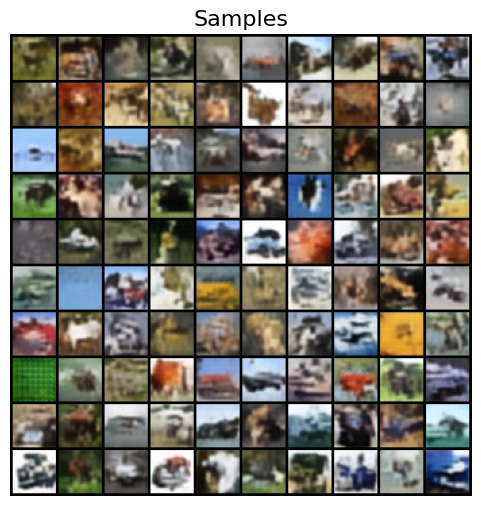

In [ ]:
N_SAMPLES = 100
model.eval()
prior_model.eval()
indices = prior_model.sample(N_SAMPLES)
with torch.no_grad():
    quantized = model.vq_layer.get_quantized(
        torch.from_numpy(indices).to(model.device)
    )
    samples = 0.5 * torch.clamp(
        model.decoder(quantized), -1, 1
    ) + 0.5
    samples = samples.cpu().numpy()

samples = samples.astype("float32")
show_samples(samples, title="Samples")